# 02 · Huấn luyện bộ phân loại VSL

Huấn luyện trên **mọi lớp đang có trong dataset** (lớp đủ số mẫu tối thiểu). Sau khi đổi extractor hoặc quy tắc padding, chạy `reextract_features.ipynb` trước để tạo lại feature từ video gốc. Quy trình: đọc dataset → đánh giá k-fold →
hiệu chỉnh xác suất → model toàn bộ dữ liệu → lưu `ensemble.pt`, `classes.json`, `metrics.json`, `vsl_classifier.onnx`.

In [55]:
import sys, json, importlib
from datetime import datetime
from pathlib import Path

import numpy as np

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir()), Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

feature_module = importlib.reload(importlib.import_module('src.features.extract'))
importlib.reload(importlib.import_module('src.features.schema'))  # schema giữ FRAME_FEATURE_DIM cũ nếu không reload
reader_module = importlib.reload(importlib.import_module('src.data.data_reader'))
tv = importlib.reload(importlib.import_module('src.model.training'))
DataHandler = reader_module.DataHandler
FEATURE_VERSION = feature_module.FEATURE_VERSION
process_sequence = feature_module.process_sequence
SEQ_FEATURE_DIM = feature_module.SEQ_FEATURE_DIM

# ============================ CẤU HÌNH HUẤN LUYỆN ============================
FOLDS = 5
MIN_SAMPLES_PER_CLASS = FOLDS      # tính theo mẫu gốc độc lập, không tính bản tăng cường
# Chỉ train trên N mẫu GỐC đầu tiên của mỗi lớp (theo id tăng dần) + bản tăng cường của chúng; -1 = toàn bộ
N_SAMPLES_PER_CLASS = int(input(f"Số mẫu gốc đầu tiên mỗi lớp để train (-1 = toàn bộ, tối thiểu {FOLDS}): "))
if N_SAMPLES_PER_CLASS != -1 and N_SAMPLES_PER_CLASS < FOLDS:
    raise ValueError(f"N_SAMPLES_PER_CLASS phải là -1 hoặc >= FOLDS={FOLDS} (mỗi fold cần ít nhất 1 mẫu gốc/lớp)")
GROUP_BY = "auto"                  # "auto" | "session" | "sample"  (xem ô giải thích bên dưới)
EPOCHS = 200
HEAD = "linear"                    # "linear" | "cosine"
HARD_NEGATIVE_MARGIN = 0.8      # Khoảng cách logit với lớp cạnh tranh mạnh nhất
HARD_NEGATIVE_WEIGHT = 0.25    # Đặt 0 để tắt margin loss
MIXUP_ALPHA = 0.0              # Trộn hai dấu gần giống có thể xoá chi tiết phân biệt
ADD_FULL_MODEL = True              # thêm 1 model train trên toàn bộ dữ liệu vào ensemble
SEED = 42
OUT_DIR = PROJECT_ROOT / "runs" / datetime.now().strftime("vsl_%Y%m%d_%H%M%S")

## 1 · Đọc dataset

In [56]:
handler = DataHandler(processor=process_sequence, min_samples_per_class=MIN_SAMPLES_PER_CLASS)
n = handler.refresh_dataset()

counts = handler.get_class_counts()
origins = handler.get_origin_counts()
active = set(handler.active_class_names)
print(f"{'Lớp':<28}{'Tổng':>8}{'Gốc':>8}  Trạng thái")
print("-" * 52)
for name, c in counts.items():
    print(f"{name:<28}{c:>8}{origins[name]:>8}  {'dùng để train' if name in active else f'BỎ QUA (< {MIN_SAMPLES_PER_CLASS} mẫu gốc)'}")
print("-" * 52)
print(f"Dùng {len(active)}/{len(counts)} lớp, {n} mẫu")

if handler.incomplete:
    print("\n[cảnh báo] mẫu dở dang/hỏng bị bỏ qua:")
    for path, why in handler.incomplete:
        print("  ", path, "->", why)
if n == 0 or len(active) < 2:
    raise RuntimeError("Chưa đủ dữ liệu: cần ít nhất 2 lớp, mỗi lớp ≥ MIN_SAMPLES_PER_CLASS mẫu.")
stale = []
for name in active:
    for sample_dir in (handler.processed / name).iterdir():
        if sample_dir.is_dir() and not sample_dir.name.startswith('.'):
            meta = handler._read_meta(sample_dir)
            if meta.get('feature_version', 1) < FEATURE_VERSION:
                stale.append(f'{name}/{sample_dir.name}')
if stale:
    raise RuntimeError(f'{len(stale)} mẫu dùng feature cũ (ví dụ {stale[:5]}). Chạy reextract_features.ipynb rồi train lại.')

# Mẫu chất lượng thấp (nhiều frame mất pose / không có tay) -> nên quay lại hoặc xoá
bad = [r for r in handler.quality_report()
       if r["pose_coverage"] < 0.8 or (r["left_hand"] == 0 and r["right_hand"] == 0)]
print(f"\n{len(bad)} mẫu chất lượng thấp" + (" (xoá bằng handler.remove_sample(lớp, id)):" if bad else ""))
for r in bad[:15]:
    print(f"  {r['class']}/{r['sample_id']} pose={r['pose_coverage']:.0%} tayT={r['left_hand']:.0%} tayP={r['right_hand']:.0%}")

Lớp                             Tổng     Gốc  Trạng thái
----------------------------------------------------
a                                130       5  dùng để train
age                              130      15  dùng để train
b                                130       5  dùng để train
cảm ơn                           130      15  dùng để train
dấu huyền                        130       5  dùng để train
dấu nặng                         130      15  dùng để train
dấu sắc                          130       5  dùng để train
dấu â,ô,ê                        130       5  dùng để train
dấu ơ,ư                          130       5  dùng để train
e                                130       5  dùng để train
g                                130      15  dùng để train
h                                130      30  dùng để train
i                                130      15  dùng để train
k                                130      15  dùng để train
l                                130       5  dùng

## 2 · Chuẩn bị dữ liệu và cách chia fold
- `GROUP_BY="sample"`: mẫu gốc và mọi bản tăng cường của nó luôn chung một fold; các lần quay khác trong cùng buổi vẫn có thể rơi vào train và val → điểm CV có thể lạc quan.
- `GROUP_BY="session"`: cả một buổi quay nằm chung một fold → đo khả năng tổng quát qua **buổi quay khác** (trung thực hơn, thường thấp hơn).
  Chỉ dùng được khi mọi lớp có ≥ `FOLDS` buổi quay; `"auto"` tự chọn `session` nếu đủ, không thì `sample`. Validation chỉ chấm mẫu gốc, không chấm bản tăng cường.

`N_SAMPLES_PER_CLASS` (nhập ở ô cấu hình): mỗi lớp chỉ giữ N mẫu **gốc** có id nhỏ nhất cùng mọi bản tăng cường của chính chúng; bản tăng cường của mẫu gốc bị loại cũng bị loại theo (không rò rỉ). Lớp có ít hơn N mẫu gốc thì dùng hết.

In [57]:
# ## 2 · Chuẩn bị dữ liệu và cách chia fold
# - `GROUP_BY="sample"`: mẫu gốc và mọi bản tăng cường của nó luôn chung một fold; các lần quay khác trong cùng buổi vẫn có thể rơi vào train và val → điểm CV có thể lạc quan.
# - `GROUP_BY="session"`: cả một buổi quay nằm chung một fold → đo khả năng tổng quát qua **buổi quay khác** (trung thực hơn, thường thấp hơn).
#   Chỉ dùng được khi mọi lớp có ≥ `FOLDS` buổi quay; `"auto"` tự chọn `session` nếu đủ, không thì `sample`. Validation chỉ chấm mẫu gốc, không chấm bản tăng cường.

# `N_SAMPLES_PER_CLASS` (nhập ở ô cấu hình): mỗi lớp chỉ giữ N mẫu **gốc** có id nhỏ nhất cùng mọi bản tăng cường của chính chúng; bản tăng cường của mẫu gốc bị loại cũng bị loại theo (không rò rỉ). Lớp có ít hơn N mẫu gốc thì dùng hết

In [58]:
data = handler.export_arrays(group_by="sample")
# Khoá "lớp/id" + thời điểm tạo của từng mẫu (cùng thứ tự export_arrays): ghi vào samples.json để
# vsl_model_finetuner biết chính xác mẫu nào là MỚI (kể cả mẫu bị N_SAMPLES_PER_CLASS để dành)
refs = [handler.describe(i) for i in range(len(handler))]
sample_keys = np.array([f"{r['class']}/{r['sample_id']}" for r in refs], dtype=object)
sample_created = np.array([str(handler._read_meta(handler._class_dir(handler.processed, r["class"]) / r["sample_id"])
                               .get("created", "")) for r in refs], dtype=object)
if N_SAMPLES_PER_CLASS != -1:
    origin_of = data["groups"]                     # "lớp/origin_id": bản tăng cường mang id của mẫu gốc
    selected = set()
    print(f"Giữ {N_SAMPLES_PER_CLASS} mẫu gốc đầu tiên mỗi lớp:")
    for c, name in enumerate(data["classes"]):
        originals = list(dict.fromkeys(origin_of[(data["y"] == c) & ~data["augmented"]]))   # thứ tự id tăng dần
        chosen = originals[:N_SAMPLES_PER_CLASS]
        selected.update(chosen)
        note = f"  [chỉ có {len(originals)} < {N_SAMPLES_PER_CLASS}, dùng hết]" if len(originals) < N_SAMPLES_PER_CLASS else ""
        print(f"  {name:<20} {len(chosen)}/{len(originals)} gốc{note}")
    keep = np.isin(origin_of, list(selected))
    data = {**data, **{key: data[key][keep] for key in ("X", "y", "groups", "sessions", "augmented")}}
    sample_keys, sample_created = sample_keys[keep], sample_created[keep]
    print(f"-> {keep.sum()}/{len(keep)} mẫu ({(~data['augmented']).sum()} gốc, {data['augmented'].sum()} tăng cường)")
X, y, classes = data["X"], data["y"], data["classes"]
sessions = data["sessions"]

sessions_per_class = [len(set(sessions[y == c])) for c in range(len(classes))]
if GROUP_BY == "auto":
    use_session = min(sessions_per_class) >= FOLDS
else:
    use_session = GROUP_BY == "session"
groups = sessions if use_session else data["groups"]
validation_mask = ~data['augmented']
for group in np.unique(groups):
    members = groups == group
    if not validation_mask[members].any():
        raise RuntimeError(f'Group {group} không có mẫu gốc để đánh giá')
for c, name in enumerate(classes):
    independent = len(np.unique(groups[(y == c) & validation_mask]))
    if independent < FOLDS:
        raise RuntimeError(f'{name}: chỉ có {independent} group gốc, cần ít nhất {FOLDS} để chia fold')

print(f"X {X.shape} (N, T, D) | {len(classes)} lớp | {validation_mask.sum()} mẫu gốc để validation | D mong đợi = {SEQ_FEATURE_DIM}")
print(f"Chia fold theo: {'session' if use_session else 'sample'} "
      f"(số session mỗi lớp: min {min(sessions_per_class)}, max {max(sessions_per_class)})")
if not use_session and GROUP_BY == "auto":
    print("  -> chưa đủ buổi quay cho mọi lớp; điểm CV có thể lạc quan. Quay thêm ở nhiều buổi khác nhau để chia theo session.")

cache = PROJECT_ROOT / "data" / "cache"
cache.mkdir(parents=True, exist_ok=True)
np.savez_compressed(cache / "dataset.npz", X=X, y=y, classes=np.array(classes),
                    groups=groups, sessions=sessions, augmented=data['augmented'])
print("Đã lưu cache:", cache / "dataset.npz")

  đã đọc 100/3480 mẫu
  đã đọc 200/3480 mẫu
  đã đọc 300/3480 mẫu
  đã đọc 400/3480 mẫu
  đã đọc 500/3480 mẫu
  đã đọc 600/3480 mẫu
  đã đọc 700/3480 mẫu
  đã đọc 800/3480 mẫu
  đã đọc 900/3480 mẫu
  đã đọc 1000/3480 mẫu
  đã đọc 1100/3480 mẫu
  đã đọc 1200/3480 mẫu
  đã đọc 1300/3480 mẫu
  đã đọc 1400/3480 mẫu
  đã đọc 1500/3480 mẫu
  đã đọc 1600/3480 mẫu
  đã đọc 1700/3480 mẫu
  đã đọc 1800/3480 mẫu
  đã đọc 1900/3480 mẫu
  đã đọc 2000/3480 mẫu
  đã đọc 2100/3480 mẫu
  đã đọc 2200/3480 mẫu
  đã đọc 2300/3480 mẫu
  đã đọc 2400/3480 mẫu
  đã đọc 2500/3480 mẫu
  đã đọc 2600/3480 mẫu
  đã đọc 2700/3480 mẫu
  đã đọc 2800/3480 mẫu
  đã đọc 2900/3480 mẫu
  đã đọc 3000/3480 mẫu
  đã đọc 3100/3480 mẫu
  đã đọc 3200/3480 mẫu
  đã đọc 3300/3480 mẫu
  đã đọc 3400/3480 mẫu
Giữ 60 mẫu gốc đầu tiên mỗi lớp:
  a                    5/5 gốc  [chỉ có 5 < 60, dùng hết]
  age                  15/15 gốc  [chỉ có 15 < 60, dùng hết]
  b                    5/5 gốc  [chỉ có 5 < 60, dùng hết]
  cảm ơn         

## 3 · Huấn luyện

In [59]:
cfg = tv.Config(max_epochs=EPOCHS, head=HEAD, seed=SEED,
                hard_negative_margin=HARD_NEGATIVE_MARGIN,
                hard_negative_weight=HARD_NEGATIVE_WEIGHT, mixup_alpha=MIXUP_ALPHA,
                # thắng thang P2 (S6 = S4b + Q3): giảm đổi nhãn khi tay thứ 2 lọt khung, tách cặp gần giống tốt hơn, xem runs/experiments/p2
                presence_norm=True, distractor_geometry=True, select_after_warmup=5)
result = tv.run_training(
    X, y, classes, groups,
    out_dir=OUT_DIR, cfg=cfg, folds=FOLDS, add_full=ADD_FULL_MODEL,
    validation_mask=validation_mask,
)
(Path(result["out_dir"]) / "samples.json").write_text(json.dumps(    # cho vsl_model_finetuner
    {str(k): str(t) for k, t in zip(sample_keys, sample_created)}, ensure_ascii=False), encoding="utf-8")
print("\nKết quả lưu tại:", result["out_dir"])

Dữ liệu: N=3480, T=30, D=418, lớp=27, mẫu/lớp: min 100 max 130 | nhóm cột: [(0, 61), (61, 137), (137, 257), (257, 347), (347, 365), (365, 367), (367, 406), (406, 418)] | thiết bị: mps

=== Fold 1/5: train 2783 | val 65 ===
  [f1] ep   1 | train aug 0.459 clean 0.959 | val_loss 0.626 acc 0.985 top5 1.000 | s=0.5 lr_x=1.00 | best nan@1 | 3s
  [f1] ep   5 | train aug 0.972 clean 0.980 | val_loss 0.070 acc 1.000 top5 1.000 | s=0.5 lr_x=1.00 | best nan@1 | 14s
  [f1] ep  10 | train aug 0.976 clean 0.986 | val_loss 0.091 acc 1.000 top5 1.000 | s=0.5 lr_x=1.00 | best 1.000@10 | 36s
  [f1] ep  15 | train aug 0.978 clean 0.986 | val_loss 0.099 acc 1.000 top5 1.000 | s=0.5 lr_x=0.50 | best 1.000@10 | 63s
  [f1] ep  20 | train aug 0.976 clean 0.986 | val_loss 0.101 acc 1.000 top5 1.000 | s=0.5 lr_x=0.28 | best 1.000@10 | 78s
  [f1] ep  25 | train aug 0.977 clean 0.986 | val_loss 0.101 acc 1.000 top5 1.000 | s=0.5 lr_x=0.25 | best 1.000@10 | 101s
  [f1] ep  30 | train aug 0.977 clean 0.986 | val_l

/Users/trungtran/Desktop/vsl-translator-new/src/model/training.py:197: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if feature_dim not in (FEATURE_DIM, SEQ_FEATURE_DIM):


## 4 · Xem kết quả

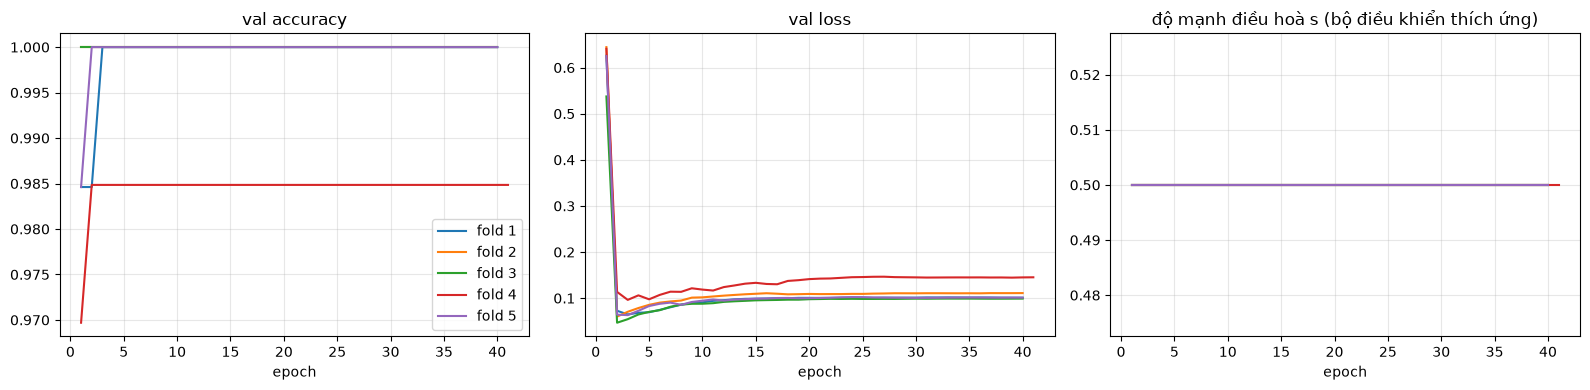

CV acc = 0.997 ± 0.006
Đối thủ gần nhất trên mẫu validation gốc:
  cảm ơn → xin chào: 4.1%
  toi → y: 1.0%
  n → m: 0.8%
  o → cảm ơn: 0.6%
  g → dấu huyền: 0.4%
  h → k: 0.4%
  t → dấu sắc: 0.4%
  l → a: 0.4%
  dấu nặng → ten_la: 0.4%
  y → b: 0.4%
1 clip gốc bị nhầm:
  cảm ơn/0: cảm ơn → xin chào
Lớp khó nhất: cảm ơn (0.93), a (1.00), age (1.00), b (1.00), dấu huyền (1.00), dấu nặng (1.00), dấu sắc (1.00), dấu â,ô,ê (1.00), dấu ơ,ư (1.00), e (1.00)


In [60]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, hist in enumerate(result["fold_histories"]):
    ep = [h["epoch"] for h in hist]
    ax[0].plot(ep, [h["val_acc"] for h in hist], label=f"fold {i+1}")
    ax[1].plot(ep, [h["val_loss"] for h in hist])
    ax[2].plot(ep, [h["strength"] for h in hist])
ax[0].set_title("val accuracy"); ax[0].legend()
ax[1].set_title("val loss")
ax[2].set_title("độ mạnh điều hoà s (bộ điều khiển thích ứng)")
for a in ax:
    a.set_xlabel("epoch"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Độ chính xác từng lớp trên dự đoán out-of-fold (lớp yếu nhất)
oof, mask, yy = result["oof_logits"], result["oof_mask"], result["y"]
pred = oof.argmax(1)
per_class = sorted(
    (float((pred[mask & (yy == c)] == c).mean()), result["classes"][c])
    for c in range(len(result["classes"])) if (mask & (yy == c)).any()
)
print(f"CV acc = {result['cv_acc_mean']:.3f} ± {result['cv_acc_std']:.3f}")
print('Đối thủ gần nhất trên mẫu validation gốc:')
for pair in result['closest_rivals'][:10]:
    print(f"  {pair['actual']} → {pair['rival']}: {pair['mean_rival_probability']:.1%}")
mistakes = np.where(mask & (pred != yy))[0]
print(f'{len(mistakes)} clip gốc bị nhầm:')
for i in mistakes:
    print(f"  {data['groups'][i]}: {classes[yy[i]]} → {classes[pred[i]]}")
print("Lớp khó nhất:", ", ".join(f"{n} ({a:.2f})" for a, n in per_class[:10]))

## 5 · Kiểm tra nhanh model đã lưu
Các mẫu dưới đây model toàn bộ dữ liệu đã **thấy khi train** — chỉ để kiểm tra pipeline nạp/dự đoán chạy đúng, **không phải** thước đo độ chính xác (hãy xem CV ở trên).

In [61]:
ens, ck = tv.load_ensemble(Path(result["out_dir"]) / "ensemble.pt")
print(f"Đã nạp ensemble: {len(ens.models)} model | T={ck['temperature']:.2f} | ngưỡng từ chối={ck['reject_threshold']:.2f}")

rng = np.random.default_rng(0)
for i in rng.choice(len(handler), size=min(5, len(handler)), replace=False):
    raw = handler.load_raw(int(i))                       # đặc trưng thô (T, FEATURE_DIM=143), giống lúc chạy thực tế
    seq = process_sequence(raw)                          # (30, SEQ_FEATURE_DIM=182)
    top = tv.predict_topk(ens, seq, ck["classes"], k=3, reject_threshold=ck["reject_threshold"])[0]
    true = handler.describe(int(i))["class"]
    print(f"thật: {true:<20} -> " + ", ".join(f"{n} {p:.2f}" for n, p in top))

Đã nạp ensemble: 6 model | T=1.00 | ngưỡng từ chối=0.20
thật: o                    -> o 0.92, dấu sắc 0.00, dấu â,ô,ê 0.00
thật: k                    -> k 0.92, dấu â,ô,ê 0.00, o 0.00
thật: dấu â,ô,ê            -> dấu â,ô,ê 0.91, a 0.00, toi 0.00
thật: dấu ơ,ư              -> dấu ơ,ư 0.92, age 0.00, toi 0.00
thật: u                    -> u 0.91, dấu nặng 0.00, v 0.00


## 6 · Dùng trong ứng dụng
Trong thư mục `OUT_DIR`:
- `vsl_classifier.onnx`: input `features` **(B, 30, 170)** là đầu ra `process_sequence` (chưa chuẩn hoá — đã gồm chuẩn hoá + ensemble); output `probs`.
- `classes.json`: tên lớp theo thứ tự chỉ số của `probs`. Dùng ngưỡng `reject_threshold` trong `metrics.json` để báo "không nhận ra".
- `ensemble.pt`: dùng với `src.model.training.load_ensemble` / `predict_topk` trong Python.

Khi inference phải dùng **đúng** extractor, `process_sequence`, model MediaPipe và `MIRROR_DATA` như lúc thu thập.